# Klasyfikacja gatunków kwiatów (fine-grained): Oxford Flowers 102

Notebook przechodzi przez wszystkie wymagania z `zadanie.md`:

1. **Dane i analiza danych**: liczba przykładów, rozkład klas, rozmiary obrazów, siatka klas
2. **Modele i wyniki**: baseline (ResNet-18, zamrożone ciało) i 4 warianty na tym samym podziale 80/10/10 (seed 6102), próg 0,84
3. **Krzywe treningowe**
4. **Eksperyment**: głębokość fine-tuningu (zamrożone / ostatni blok / całość), jakość vs czas treningu
5. **Ewaluacja na żywo** najlepszego modelu z **własnym licznikiem top-k** (`TopKCounter`)
6. **Analiza błędów**: confusion matrix, mylone pary, błędne predykcje, „mała liczba przykładów czy istota problemu?”
7. **Demo**: predykcje top-3 na zdjęciach testowych i na własnym zdjęciu

Eksperymenty w W&B: [metashi-dsw/oxford-flowers102-finetuning](https://forge.coreweave.com/wandb/metashi-dsw/oxford-flowers102-finetuning)

**Wymagania:** dane przygotowane przez `python src/data.py` i wagi z `python src/train.py --run <wariant>` (albo `src/run_all.sh`). Wag ani danych nie ma w repozytorium. Pozostałe sekcje czytają wyniki zapisane w `results/`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy.stats import spearmanr
from torch.utils.data import DataLoader

import config as C
from data import prepare, class_names, get_transforms, FlowersDataset
from models import build_model
from metrics import TopKCounter, macro_f1, confusion
from utils import get_device, set_seed
from evaluate import load_runs, confused_pairs, LABELS, THRESHOLD

# evaluate.py przełącza matplotlib na backend Agg (zapis do plików), wracamy do wykresów inline
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]  # mniejszy plik notebooka
import matplotlib.pyplot as plt

set_seed(C.SEED)
device = get_device()
names = class_names()
df = prepare()
runs, summ, hist, preds = load_runs()
print("urządzenie:", device, "| warianty:", runs)

urządzenie: mps | warianty: ['r18_frozen', 'r18_last_block', 'r18_full', 'mnv2_frozen', 'mnv2_full']


## 1. Dane

Zbiór: 8 189 zdjęć, 102 gatunki. Etykiety pochodzą z oficjalnego `imagelabels.mat` (Oxford VGG). Podział jest własny, stratyfikowany 80/10/10 z `random_state=6102` (`splits/split_seed6102.csv`), więc każda klasa występuje w każdej części.

liczba zdjęć: 8189 | klas: 102
podział: {'train': 6551, 'test': 819, 'val': 819}
zdjęć na klasę: min 40, max 258, średnia 80.3, mediana 66, max/min = 6.45


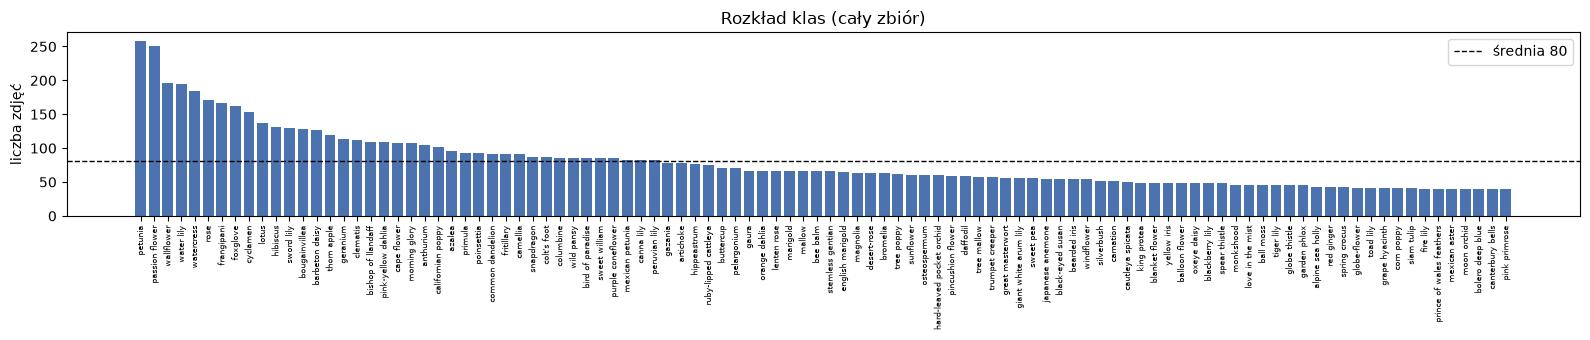

In [2]:
counts = df.label.value_counts().sort_index()
print("liczba zdjęć:", len(df), "| klas:", df.label.nunique())
print("podział:", df.split.value_counts().to_dict())
print(f"zdjęć na klasę: min {counts.min()}, max {counts.max()}, średnia {counts.mean():.1f}, "
      f"mediana {counts.median():.0f}, max/min = {counts.max() / counts.min():.2f}")
assert all(df[df.split == s].label.nunique() == C.NUM_CLASSES for s in ("train", "val", "test"))

fig, ax = plt.subplots(figsize=(16, 3.5))
order = counts.sort_values(ascending=False)
ax.bar(range(len(order)), order.values, color="#4C72B0")
ax.set_xticks(range(len(order)))
ax.set_xticklabels([names[i] for i in order.index], rotation=90, fontsize=6)
ax.axhline(counts.mean(), color="k", ls="--", lw=1, label=f"średnia {counts.mean():.0f}")
ax.set_ylabel("liczba zdjęć"); ax.set_title("Rozkład klas (cały zbiór)"); ax.legend()
plt.tight_layout(); plt.show()

Zbiór jest **niezbalansowany** (stosunek największej klasy do najmniejszej to 6,5:1). Dlatego obok accuracy raportujemy **macro-F1**, w którym każda klasa waży tyle samo.

Rozmiary oryginalnych obrazów (przed przeskalowaniem do krótszego boku 256 px):

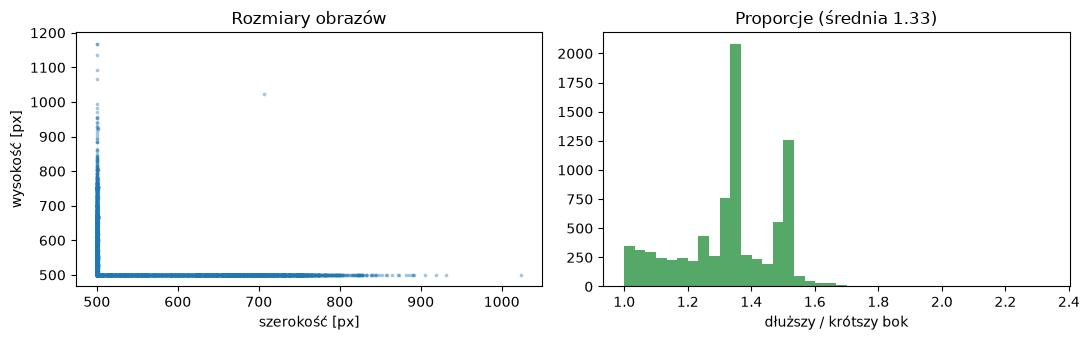

krótszy bok == 500 px: 95.6%


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].scatter(df.orig_w, df.orig_h, s=3, alpha=0.3)
axes[0].set_xlabel("szerokość [px]"); axes[0].set_ylabel("wysokość [px]"); axes[0].set_title("Rozmiary obrazów")
aspect = np.maximum(df.orig_w, df.orig_h) / np.minimum(df.orig_w, df.orig_h)
axes[1].hist(aspect, bins=40, color="#55A868")
axes[1].set_xlabel("dłuższy / krótszy bok"); axes[1].set_title(f"Proporcje (średnia {aspect.mean():.2f})")
plt.tight_layout(); plt.show()
print("krótszy bok == 500 px:", f"{(np.minimum(df.orig_w, df.orig_h) == 500).mean():.1%}")

Siatka klas: po jednym losowym zdjęciu z 24 klas (pełna siatka 102 klas jest w `figures/eda_class_grid.jpg`).

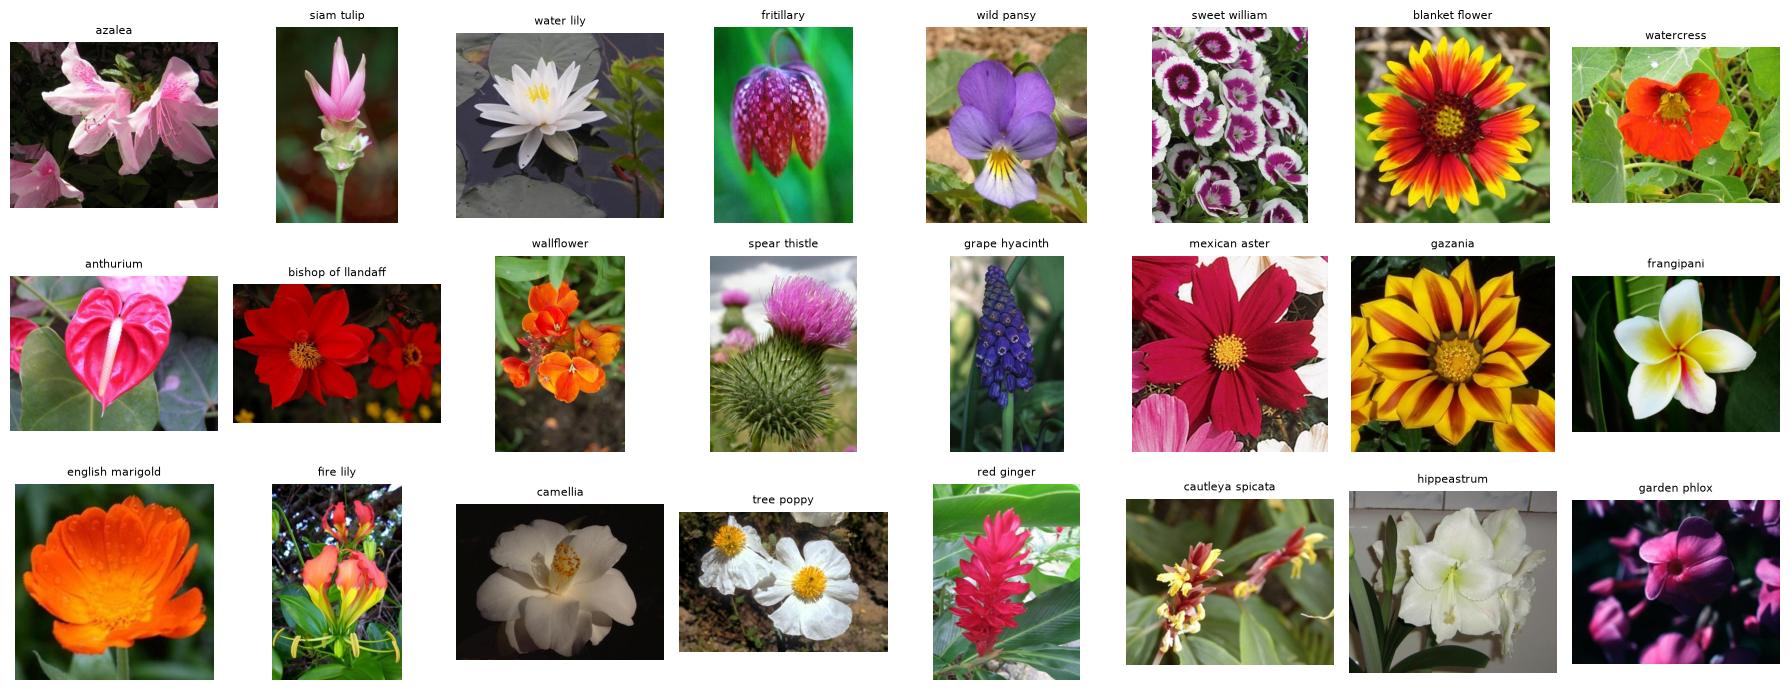

In [4]:
rng = np.random.default_rng(C.SEED)
classes = rng.choice(C.NUM_CLASSES, 24, replace=False)
fig, axes = plt.subplots(3, 8, figsize=(18, 7))
for ax, c in zip(axes.flat, classes):
    f = rng.choice(df[(df.label == c) & (df.split == "train")].file.values)
    ax.imshow(Image.open(C.CACHE_DIR / f)); ax.set_title(names[c], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

Zmienność wewnątrz klasy: ta sama klasa w różnych kolorach, kadrach i fazach rozkwitu. To główna trudność fine-grained, obok podobieństwa między klasami.

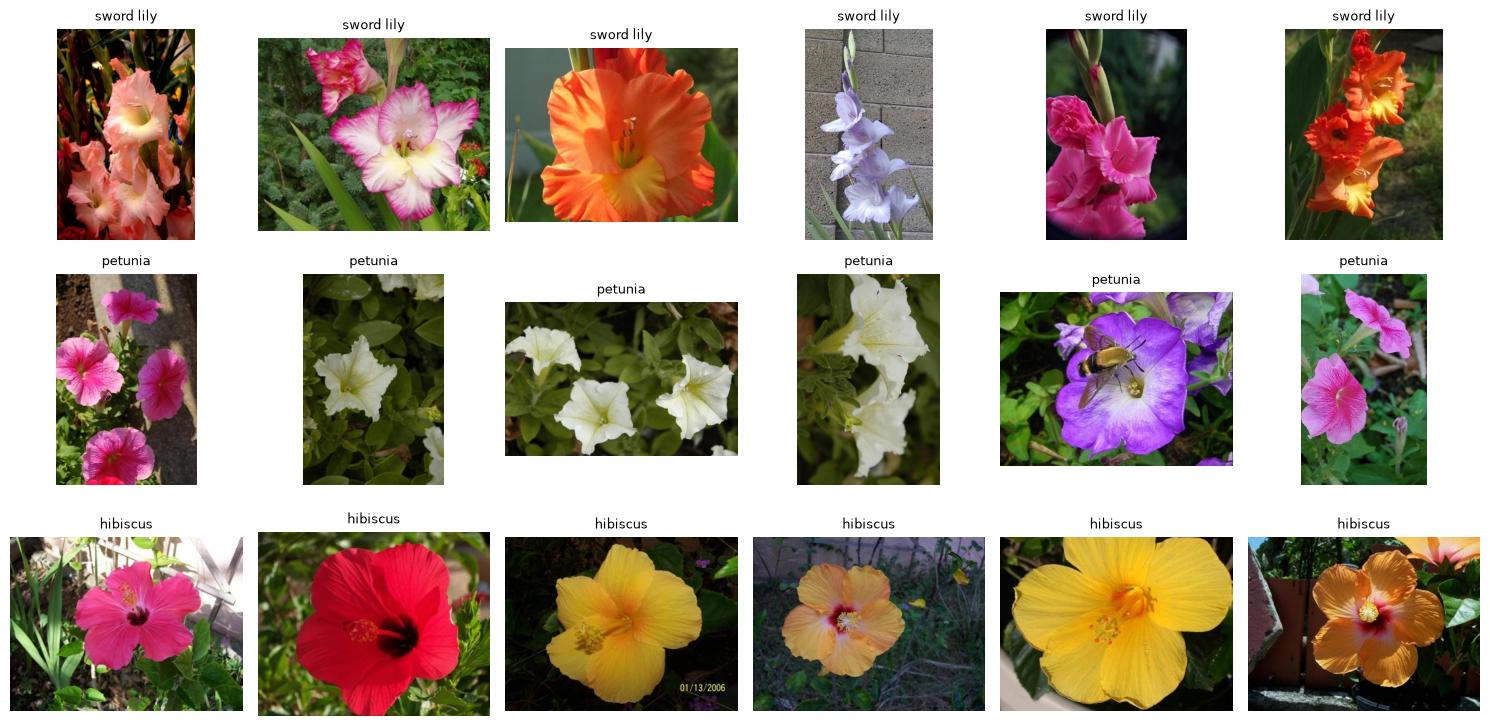

In [5]:
fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
for row, cname in zip(axes, ["sword lily", "petunia", "hibiscus"]):
    c = names.index(cname)
    for ax, f in zip(row, rng.choice(df[df.label == c].file.values, 6, replace=False)):
        ax.imshow(Image.open(C.CACHE_DIR / f)); ax.set_title(cname, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 2. Modele i wyniki

Wszystkie warianty używają wag ImageNet (`torchvision`) i różnią się architekturą oraz tym, które warstwy są trenowane:

| wariant | co trenujemy | lr głowa / ciało | epoki |
|---|---|---|---|
| `r18_frozen` (**baseline**) | tylko nowa warstwa `fc` | 1e-3 / — | 10 |
| `r18_last_block` | `layer4` + `fc` | 1e-3 / 3e-4 | 10 |
| `r18_full` | cała sieć, mały lr dla ciała | 1e-3 / 1e-4 | 12 |
| `mnv2_frozen` | tylko klasyfikator | 1e-3 / — | 10 |
| `mnv2_full` | cała sieć | 1e-3 / 1e-4 | 12 |

Wyniki na zbiorze testowym (819 zdjęć). Wszystkie metryki top-k policzył własny `TopKCounter`:

In [6]:
tab = summ.assign(wariant=summ.run.map(LABELS), trenowane_M=summ.trainable_params / 1e6,
                  czas_min=summ.train_time_s / 60)
tab = tab[["wariant", "trenowane_M", "czas_min", "test_acc", "test_macro_f1", "test_top3", "test_top5"]]
tab["próg 0.84"] = np.where(tab.test_acc >= THRESHOLD, "✅", "❌")
tab.round(3).set_index("wariant")

,trenowane_M,czas_min,test_acc,test_macro_f1,test_top3,test_top5,próg 0.84
wariant,,,,,,,
ResNet-18 zamrożony (baseline),0.052,3.671,0.906,0.893,0.969,0.987,✅
ResNet-18 ostatni blok,8.446,6.007,0.967,0.966,0.998,0.999,✅
ResNet-18 pełny FT,11.229,16.111,0.979,0.980,0.994,0.998,✅
MobileNetV2 zamrożony,0.131,2.627,0.944,0.934,0.987,0.994,✅
MobileNetV2 pełny FT,2.355,16.181,0.978,0.976,0.996,0.998,✅


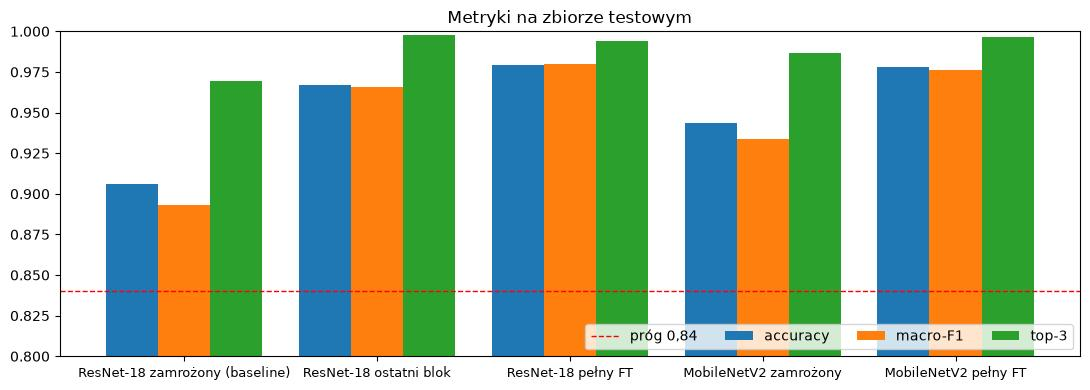

In [7]:
metrics = ["test_acc", "test_macro_f1", "test_top3"]
x = np.arange(len(runs)); w = 0.27
fig, ax = plt.subplots(figsize=(11, 4))
for i, (m, lab) in enumerate(zip(metrics, ["accuracy", "macro-F1", "top-3"])):
    ax.bar(x + (i - 1) * w, summ[m], w, label=lab)
ax.axhline(THRESHOLD, color="r", ls="--", lw=1, label="próg 0,84")
ax.set_xticks(x); ax.set_xticklabels([LABELS[r] for r in runs], fontsize=9)
ax.set_ylim(0.8, 1.0); ax.legend(ncol=4, loc="lower right"); ax.set_title("Metryki na zbiorze testowym")
plt.tight_layout(); plt.show()

Próg 0,84 osiąga **każdy** wariant, również baseline (0,906).

## 3. Krzywe treningowe

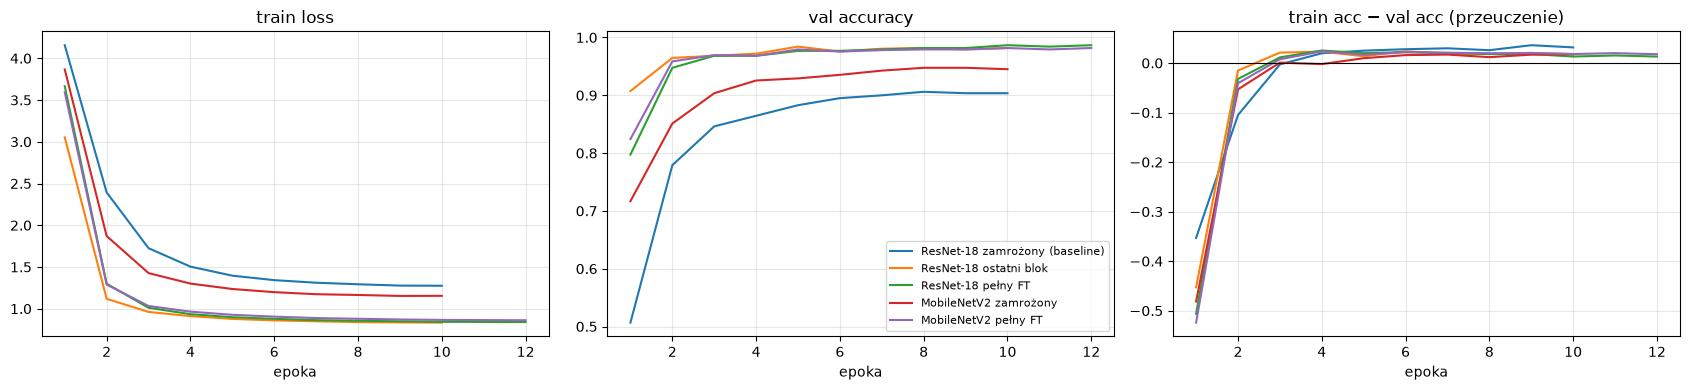

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for r in runs:
    h = hist[r]
    axes[0].plot(h.epoch, h.train_loss, label=LABELS[r])
    axes[1].plot(h.epoch, h.val_acc, label=LABELS[r])
    axes[2].plot(h.epoch, h.train_acc - h.val_acc, label=LABELS[r])
for ax, t in zip(axes, ["train loss", "val accuracy", "train acc − val acc (przeuczenie)"]):
    ax.set_title(t); ax.set_xlabel("epoka"); ax.grid(alpha=0.3)
axes[1].legend(fontsize=8); axes[2].axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

- Warianty z **zamrożonym ciałem** mają train ≈ val, więc się nie przeuczają. Ogranicza je pojemność reprezentacji ImageNet, a nie liczba danych.
- **Pełny fine-tuning** dochodzi do train accuracy ≈ 1,0 przy val ≈ 0,98. Lukę trzymają w ryzach mały lr dla ciała, label smoothing i OneCycle, ale przy większej liczbie epok rosłoby ryzyko przeuczenia.

## 4. Eksperyment: głębokość fine-tuningu (zamrożone vs ostatni blok vs całość)

In [9]:
r18 = summ[summ.arch == "resnet18"].set_index("run").loc[["r18_frozen", "r18_last_block", "r18_full"]]
exp = pd.DataFrame({
    "accuracy": r18.test_acc, "macro-F1": r18.test_macro_f1,
    "czas [min]": r18.train_time_s / 60, "trenowane param. [M]": r18.trainable_params / 1e6})
exp["Δ acc vs poprzedni [pp]"] = exp.accuracy.diff() * 100
exp["× czasu vs poprzedni"] = exp["czas [min]"] / exp["czas [min]"].shift()
gain = (r18.test_acc.iloc[1] - r18.test_acc.iloc[0]) / (r18.test_acc.iloc[2] - r18.test_acc.iloc[0])
print(f"ostatni blok daje {gain:.0%} zysku pełnego FT przy "
      f"{r18.train_time_s.iloc[1] / r18.train_time_s.iloc[2]:.0%} jego czasu")
exp.round(3)

ostatni blok daje 83% zysku pełnego FT przy 37% jego czasu


,accuracy,macro-F1,czas [min],trenowane param. [M],Δ acc vs poprzedni [pp],× czasu vs poprzedni
run,,,,,,
r18_frozen,0.906,0.893,3.671,0.052,NaN,NaN
r18_last_block,0.967,0.966,6.007,8.446,6.105,1.636
r18_full,0.979,0.980,16.111,11.229,1.221,2.682


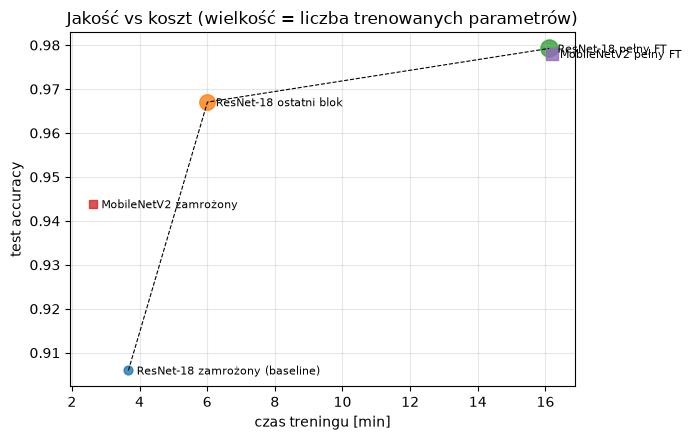

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for r in runs:
    s = summ.set_index("run").loc[r]
    ax.scatter(s.train_time_s / 60, s.test_acc, s=40 + s.trainable_params / 1e5,
               marker="o" if s.arch == "resnet18" else "s", alpha=0.8)
    ax.annotate(LABELS[r], (s.train_time_s / 60, s.test_acc), xytext=(6, -3),
                textcoords="offset points", fontsize=8)
ax.plot(r18.train_time_s / 60, r18.test_acc, "k--", lw=0.8)
ax.set_xlabel("czas treningu [min]"); ax.set_ylabel("test accuracy")
ax.set_title("Jakość vs koszt (wielkość = liczba trenowanych parametrów)"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Co się zmienia i dlaczego:**

- **Zamrożone ciało:** cechy ImageNet odróżniają „kwiat” od „psa”, ale nie „sweet william” od „carnation”. Liniowa głowa może tylko ważyć gotowe cechy, dlatego macro-F1 jest niższe od accuracy: cierpią klasy podobne do siebie.
- **Ostatni blok (`layer4`):** największy skok (+6 pp) przy 1,6 razy dłuższym treningu. `layer4` koduje części obiektu i tekstury, czyli to, co trzeba przestroić na detale kwiatów (kształt płatków, pręciki, żyłki). Niższe warstwy (krawędzie, kolory) są uniwersalne.
- **Cała sieć:** jeszcze +1,2 pp, ale za 2,7 razy dłuższy trening. Wcześniejsze warstwy i tak dobrze się przenoszą.

**ResNet-18 vs MobileNetV2:** MobileNetV2 ma 4,8 razy mniej parametrów i w pełnym FT osiąga praktycznie ten sam wynik (różnica to 1 zdjęcie). Zamrożony MobileNetV2 jest lepszy od zamrożonego ResNet-18 (1 280-wymiarowe cechy zamiast 512). Na CPU w PyTorch nie jest jednak szybszy (konwolucje depthwise), więc jego przewagą jest rozmiar modelu i runtime'y mobilne.

## 5. Ewaluacja na żywo najlepszego modelu: własny licznik top-k

Ładujemy checkpoint najlepszego wariantu i jeszcze raz liczymy metryki na teście. Top-k liczy **własnoręcznie zaimplementowany** `TopKCounter` (`src/metrics.py`): sortuje logity, sprawdza, czy prawdziwa klasa jest wśród k pierwszych, i akumuluje trafienia po batchach. Nie korzysta z gotowej funkcji metryki.

In [11]:
import inspect
print(inspect.getsource(TopKCounter.update))

    def update(self, logits: torch.Tensor, targets: torch.Tensor) -> None:
        logits = logits.detach().float().cpu()
        targets = targets.detach().cpu()
        max_k = max(self.ks)
        # indeksy klas posortowane malejąco wg logitu: argsort(-x) == ranking
        ranked = torch.argsort(logits, dim=1, descending=True)[:, :max_k]
        correct = ranked == targets.unsqueeze(1)  # [B, max_k] bool, max. jedno True w wierszu
        for k in self.ks:
            self.hits[k] += int(correct[:, :k].any(dim=1).sum())
        self.total += targets.shape[0]



In [12]:
best = summ.loc[summ.test_acc.idxmax(), "run"]
cfg = C.VARIANTS[best]
model, *_ = build_model(cfg["arch"], cfg["finetune"], pretrained=False)
model.load_state_dict(torch.load(C.CKPT_DIR / f"{best}.pt", map_location="cpu"))
model.to(device).eval()

test_df = df[df.split == "test"]
loader = DataLoader(FlowersDataset(test_df, train=False), batch_size=64, num_workers=0)
counter = TopKCounter(ks=(1, 3, 5))
logits, y_true = [], []
with torch.no_grad():
    for x, y in loader:
        out = model(x.to(device)).float().cpu()
        counter.update(out, y)
        logits.append(out); y_true.append(y)
logits, y_true = torch.cat(logits), torch.cat(y_true).numpy()
probs = torch.softmax(logits, 1).numpy()
y_pred = probs.argmax(1)
live = counter.compute()

saved = summ.set_index("run").loc[best]
pd.DataFrame({"na żywo": [live[1], macro_f1(y_true, y_pred), live[3], live[5]],
              "zapisane (results/)": [saved.test_acc, saved.test_macro_f1, saved.test_top3, saved.test_top5]},
             index=["accuracy", "macro-F1", "top-3", "top-5"]).round(4).rename_axis(LABELS[best])

,na żywo,zapisane (results/)
ResNet-18 pełny FT,,
accuracy,0.9792,0.9792
macro-F1,0.9799,0.9799
top-3,0.9939,0.9939
top-5,0.9976,0.9976


Wyniki na żywo zgadzają się z zapisanymi w `results/`. Najlepszy model i podział danych odtwarzają się.

## 6. Analiza błędów

błędy: 17 / 819 | prawdziwa klasa w top-3 przy błędzie: 71%
średnia pewność: trafne 0.81, błędne 0.31


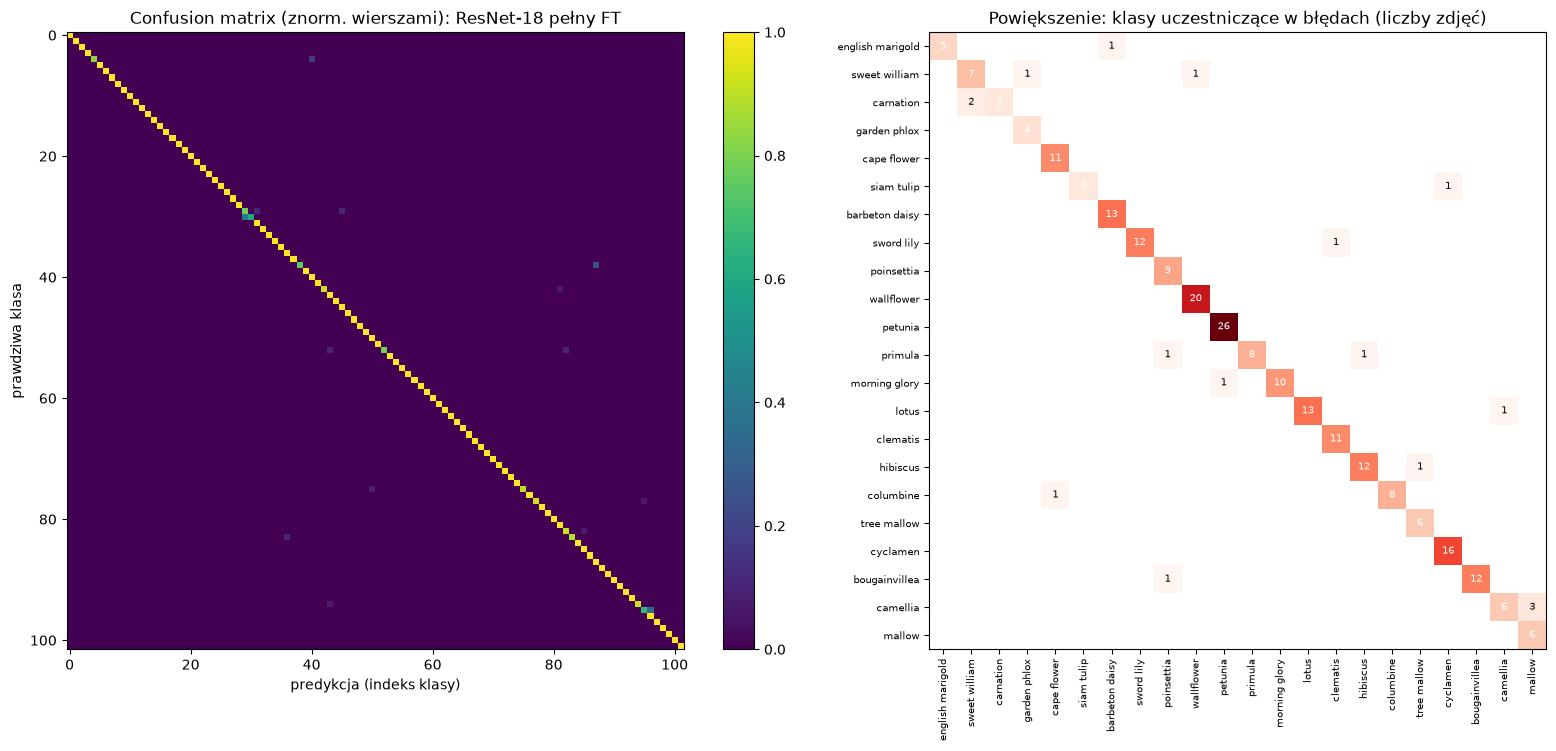

In [13]:
cm = confusion(y_true, y_pred, C.NUM_CLASSES)
wrong = y_true != y_pred
in_top3 = (np.argsort(-probs, 1)[:, :3] == y_true[:, None]).any(1)
conf = probs.max(1)
print(f"błędy: {wrong.sum()} / {len(y_true)} | prawdziwa klasa w top-3 przy błędzie: {in_top3[wrong].mean():.0%}")
print(f"średnia pewność: trafne {conf[~wrong].mean():.2f}, błędne {conf[wrong].mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), gridspec_kw=dict(width_ratios=[1.15, 1]))
cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
im = axes[0].imshow(cmn, cmap="viridis", vmin=0, vmax=1)
axes[0].set_title(f"Confusion matrix (znorm. wierszami): {LABELS[best]}")
axes[0].set_xlabel("predykcja (indeks klasy)"); axes[0].set_ylabel("prawdziwa klasa")
fig.colorbar(im, ax=axes[0], fraction=0.04)
# powiększenie: tylko klasy biorące udział w błędach
inv = sorted(set(y_true[wrong]) | set(y_pred[wrong]))
sub = cm[np.ix_(inv, inv)]
axes[1].imshow(np.where(sub > 0, sub, np.nan), cmap="Reds")
for i in range(len(inv)):
    for j in range(len(inv)):
        if sub[i, j]:
            axes[1].text(j, i, sub[i, j], ha="center", va="center", fontsize=7,
                         color="k" if i != j else "w")
axes[1].set_xticks(range(len(inv))); axes[1].set_yticks(range(len(inv)))
axes[1].set_xticklabels([names[c] for c in inv], rotation=90, fontsize=7)
axes[1].set_yticklabels([names[c] for c in inv], fontsize=7)
axes[1].set_title("Powiększenie: klasy uczestniczące w błędach (liczby zdjęć)")
plt.tight_layout(); plt.show()

Najczęściej mylone pary: najlepszy model vs baseline (wartości z obu kierunków pomyłki):

In [14]:
def pairs_table(p):
    return pd.DataFrame(confused_pairs(confusion(p.label, p.pred, C.NUM_CLASSES), names, k=8))[
        ["name_a", "name_b", "a_as_b", "b_as_a", "total"]]

print("Najlepszy model:"); display(pairs_table(preds[best]))
print("Baseline (r18_frozen):"); display(pairs_table(preds["r18_frozen"]))

Najlepszy model:


,name_a,name_b,a_as_b,b_as_a,total
0,camellia,mallow,3,0,3
1,sweet william,carnation,0,2,2
2,petunia,morning glory,0,1,1
3,siam tulip,cyclamen,1,0,1
4,primula,hibiscus,1,0,1
5,hibiscus,tree mallow,1,0,1
6,sweet william,wallflower,1,0,1
7,lotus,camellia,1,0,1


Baseline (r18_frozen):


,name_a,name_b,a_as_b,b_as_a,total
0,sweet william,azalea,2,0,2
1,petunia,bougainvillea,0,2,2
2,watercress,mallow,0,2,2
3,sweet william,carnation,0,2,2
4,camellia,mallow,2,0,2
5,canterbury bells,bougainvillea,2,0,2
6,canterbury bells,petunia,2,0,2
7,rose,anthurium,1,1,2


Błędne predykcje najlepszego modelu: tytuł pokazuje prawdziwą klasę (GT), predykcję i pewność. Obok jest losowe zdjęcie treningowe przewidzianej klasy, żeby było widać, z czym model pomylił kwiat.

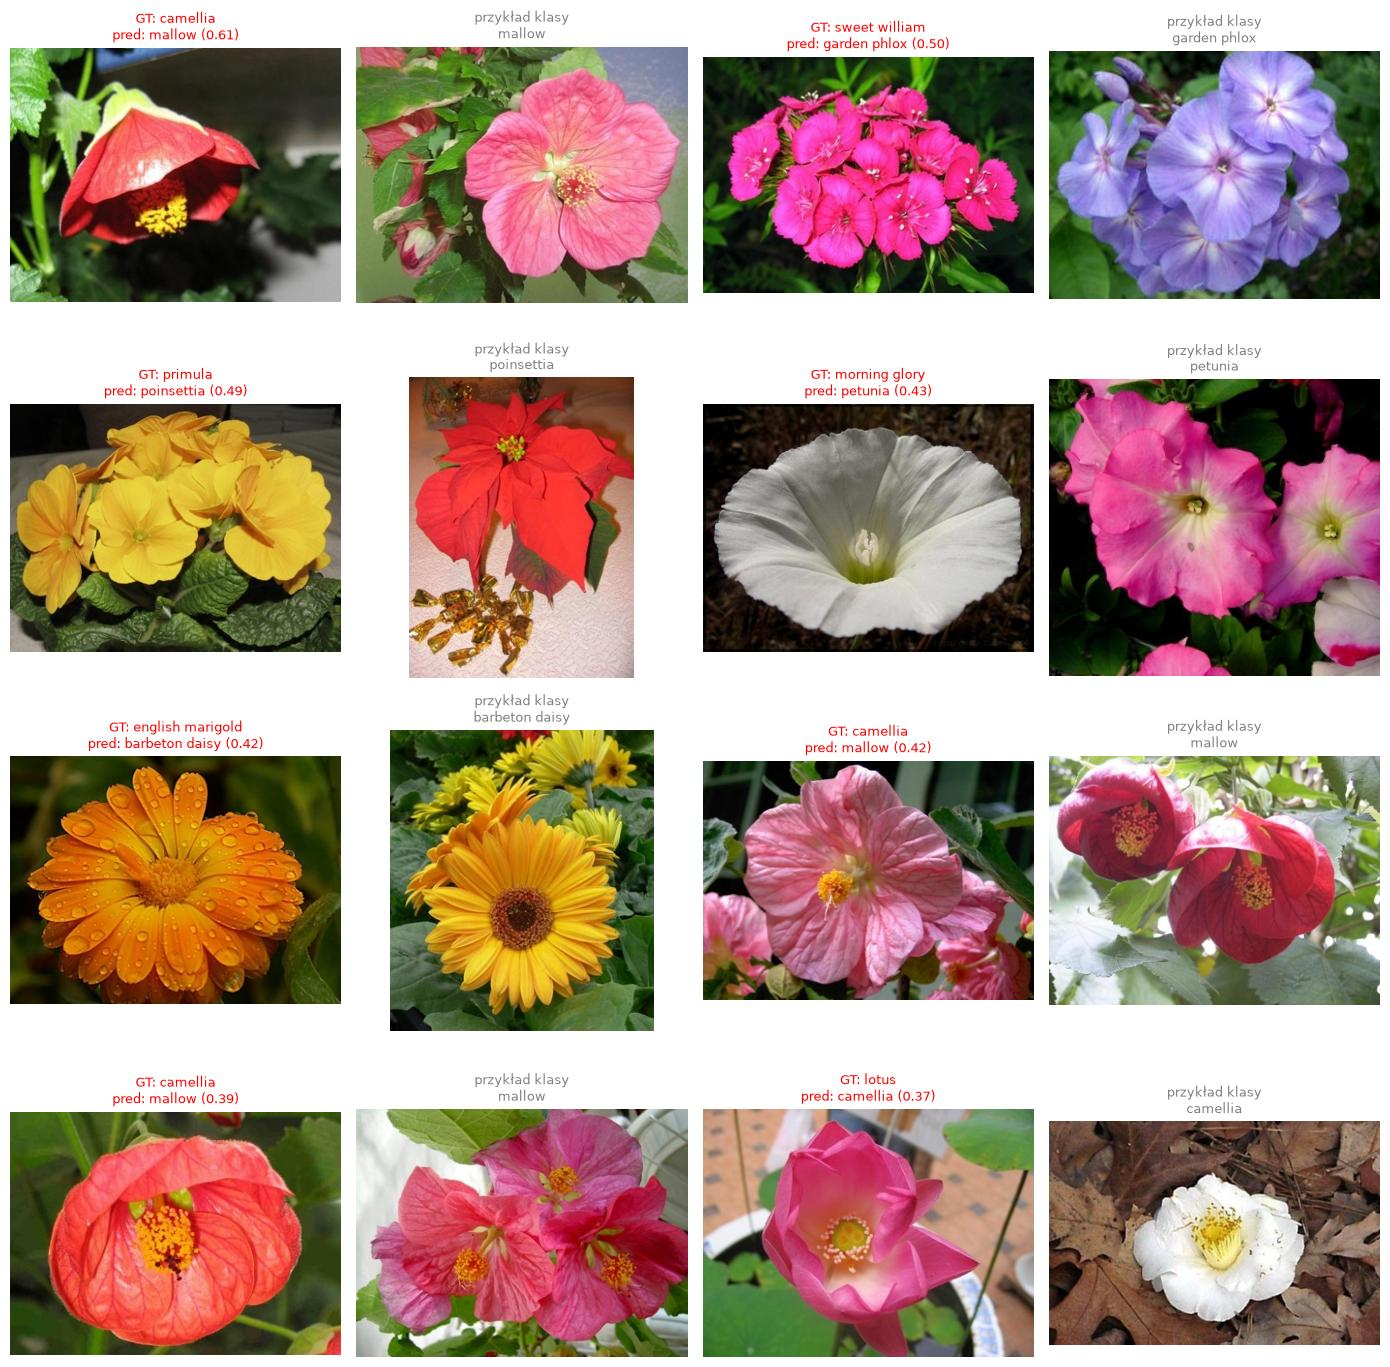

In [15]:
err_idx = np.where(wrong)[0][np.argsort(-conf[wrong])][:8]
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for k, i in enumerate(err_idx):
    ax_e, ax_r = axes.flat[2 * k], axes.flat[2 * k + 1]
    ax_e.imshow(Image.open(C.CACHE_DIR / test_df.file.iloc[i]))
    ax_e.set_title(f"GT: {names[y_true[i]]}\npred: {names[y_pred[i]]} ({conf[i]:.2f})", fontsize=9, color="red")
    ref = rng.choice(df[(df.label == y_pred[i]) & (df.split == "train")].file.values)
    ax_r.imshow(Image.open(C.CACHE_DIR / ref))
    ax_r.set_title(f"przykład klasy\n{names[y_pred[i]]}", fontsize=9, color="gray")
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.show()

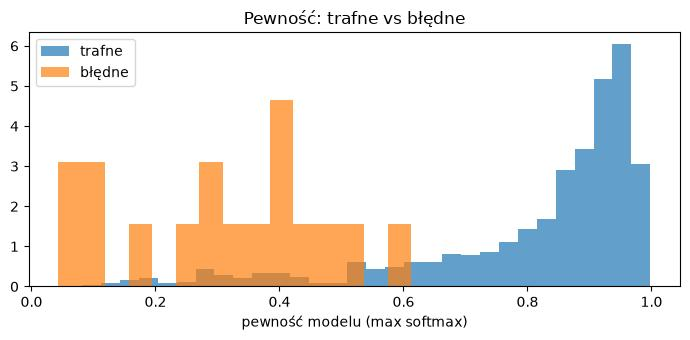

odrzucamy pewność < 0.3: odrzucone 4.3% zdjęć, accuracy na reszcie 0.987
odrzucamy pewność < 0.4: odrzucone 7.7% zdjęć, accuracy na reszcie 0.992
odrzucamy pewność < 0.5: odrzucone 9.9% zdjęć, accuracy na reszcie 0.997


In [16]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(conf[~wrong], bins=30, alpha=0.7, density=True, label="trafne")
ax.hist(conf[wrong], bins=15, alpha=0.7, density=True, label="błędne")
ax.set_xlabel("pewność modelu (max softmax)"); ax.legend(); ax.set_title("Pewność: trafne vs błędne")
plt.tight_layout(); plt.show()
for t in (0.3, 0.4, 0.5):
    keep = conf >= t
    print(f"odrzucamy pewność < {t}: odrzucone {1 - keep.mean():.1%} zdjęć, "
          f"accuracy na reszcie {(y_pred[keep] == y_true[keep]).mean():.3f}")

### Mała liczba przykładów czy istota problemu?

Jeśli błędy wynikałyby z małej liczby przykładów, F1 klasy rosłoby z liczbą jej zdjęć treningowych. Sprawdzamy korelację Spearmana dla każdego wariantu:

,spearman_rho,p_value
wariant,,
ResNet-18 zamrożony (baseline),-0.030,0.762
ResNet-18 ostatni blok,-0.109,0.274
ResNet-18 pełny FT,-0.309,0.002
MobileNetV2 zamrożony,0.046,0.648
MobileNetV2 pełny FT,-0.133,0.183


mediana zdjęć treningowych: klasy z błędami 73.5, klasy bez błędów 50.0


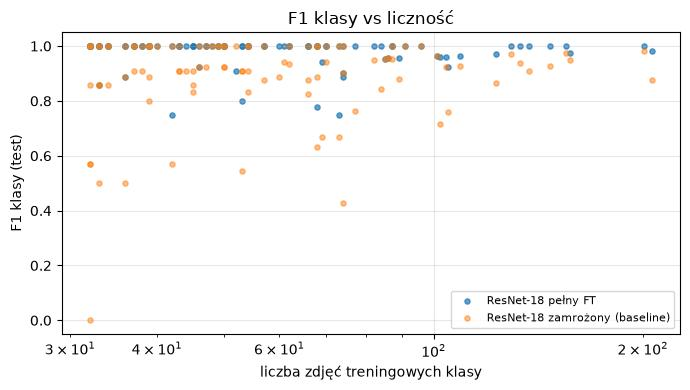

In [17]:
train_counts = df[df.split == "train"].label.value_counts().sort_index().values
pc = pd.read_csv(C.RESULTS_DIR / "per_class_metrics.csv")
rows = []
for r in runs:
    rho, p = spearmanr(train_counts, pc[f"f1_{r}"])
    rows.append(dict(wariant=LABELS[r], spearman_rho=round(rho, 3), p_value=round(p, 3)))
display(pd.DataFrame(rows).set_index("wariant"))

err_cls = pc[f"recall_{best}"] < 1
print(f"mediana zdjęć treningowych: klasy z błędami {np.median(train_counts[err_cls]):.1f}, "
      f"klasy bez błędów {np.median(train_counts[~err_cls]):.1f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(train_counts, pc[f"f1_{best}"], s=14, alpha=0.7, label=LABELS[best])
ax.scatter(train_counts, pc["f1_r18_frozen"], s=14, alpha=0.5, label=LABELS["r18_frozen"])
ax.set_xscale("log"); ax.set_xlabel("liczba zdjęć treningowych klasy"); ax.set_ylabel("F1 klasy (test)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); ax.set_title("F1 klasy vs liczność")
plt.tight_layout(); plt.show()

**Wniosek: liczba przykładów nie tłumaczy błędów.** Korelacja nigdzie nie jest dodatnia, a w najlepszym modelu jest istotnie ujemna. Najmniejsze klasy (~32 zdjęcia treningowe) są rozpoznawane bezbłędnie, bo są wizualnie unikatowe. Błędy wynikają z:

1. **Rzeczywistego podobieństwa gatunków.** Sweet william i carnation to dwa goździki (*Dianthus*) o postrzępionych płatkach. Hibiscus i tree mallow należą do ślazowatych. Siam tulip i cyclamen to różowe, wydłużone płatki widziane z boku.
2. **Dużej zmienności wewnątrz klasy.** Duże klasy (petunia, hibiscus) występują w wielu kolorach i nachodzą na inne klasy. Stąd ujemna korelacja: więcej zdjęć często oznacza bardziej heterogeniczną klasę.
3. **Szumu w etykietach.** Błędy „camellia → mallow” dotyczą zdjęć, które wyglądają na abutilon (klasa „mallow”), więc model prawdopodobnie ma rację, a etykieta jest błędna (ocena na oko, bez weryfikacji botanicznej).
4. **Kadru.** Widok z boku albo mocne zbliżenie, na którym brak cechy rozróżniającej (liści, pokroju rośliny).

Baseline myli te same rodziny, tylko dużo częściej. Fine-tuning naprawia większość błędów, ale goździki i camellia/mallow zostają, bo tam ograniczeniem są dane, a nie model.

## 7. Demo: predykcje top-3

In [18]:
tf = get_transforms(train=False)

@torch.no_grad()
def predict(img: Image.Image, k=3):
    img = img.convert("RGB")
    s = C.RESIZE_SHORT / min(img.size)  # ten sam preprocessing co przy treningu
    img = img.resize((round(img.width * s), round(img.height * s)), Image.BICUBIC)
    probs = torch.softmax(model(tf(img).unsqueeze(0).to(device)), 1)[0].cpu()
    p, i = probs.topk(k)
    return [(names[j], float(q)) for j, q in zip(i, p)]

def show(files, labels=None, cols=4):
    rows = int(np.ceil(len(files) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 4.6 * rows))
    for ax in np.atleast_1d(axes).flat: ax.axis("off")
    for ax, f, lab in zip(np.atleast_1d(axes).flat, files, labels or [None] * len(files)):
        img = Image.open(f)
        top = predict(img)
        ax.imshow(img)
        ok = lab is None or top[0][0] == names[lab]
        txt = "\n".join(f"{n}: {p:.2f}" for n, p in top)
        if lab is not None: txt = f"GT: {names[lab]}\n" + txt
        ax.set_title(txt, fontsize=9, color="green" if ok else "red")
    plt.tight_layout(); plt.show()

Losowe zdjęcia testowe (zielone = poprawnie, czerwone = błąd):

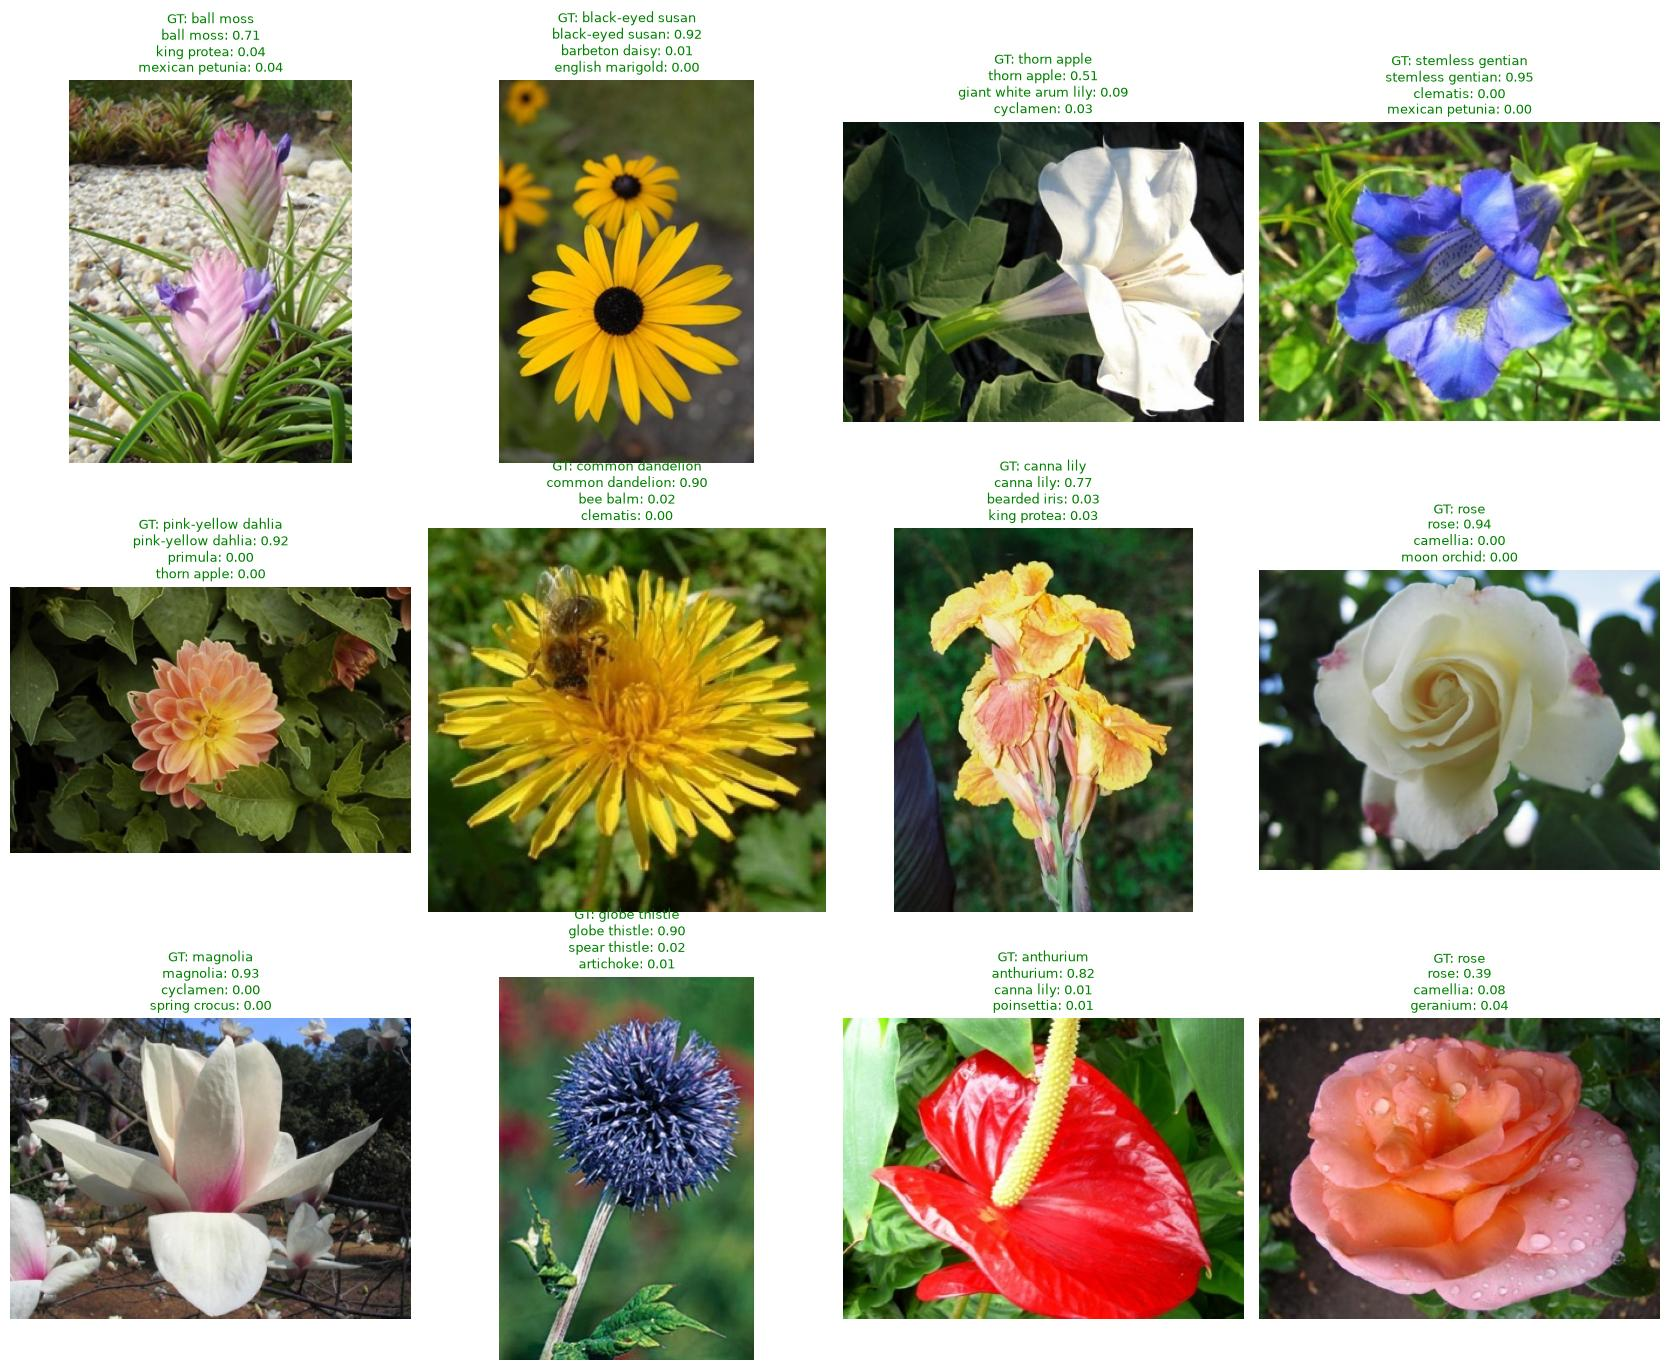

In [19]:
sample = test_df.sample(12, random_state=C.SEED)
show([C.CACHE_DIR / f for f in sample.file], sample.label.tolist())

### Własne zdjęcie
Podmień ścieżkę na dowolny plik `.jpg` ze zdjęciem kwiatu. Gdy pewność top-1 jest niska (< ~0,4), warto zrobić drugie zdjęcie, np. liści albo całej rośliny.

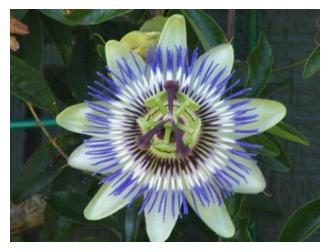

,gatunek,prawdopodobieństwo
0,passion flower,0.860
1,alpine sea holly,0.003
2,artichoke,0.003
3,water lily,0.003
4,anthurium,0.002


In [20]:
my_image = C.CACHE_DIR / test_df.file.iloc[0]  # <- tu własna ścieżka
img = Image.open(my_image)
plt.figure(figsize=(4, 4)); plt.imshow(img); plt.axis("off"); plt.show()
pd.DataFrame(predict(img, k=5), columns=["gatunek", "prawdopodobieństwo"]).round(3)

## Podsumowanie

- **Wynik:** ResNet-18 z pełnym fine-tuningiem osiąga accuracy 0,979, macro-F1 0,980 i top-3 0,994. Próg 0,84 przekracza każdy wariant, łącznie z baseline'em (0,906).
- **Eksperyment:** odmrożenie ostatniego bloku daje ~83% zysku pełnego fine-tuningu przy ~37% jego czasu. To najlepszy kompromis jakości i kosztu.
- **Architektura:** MobileNetV2 dorównuje ResNet-18 przy 4,8 razy mniejszej liczbie parametrów, więc to dobry wybór na telefon (CoreML/TFLite).
- **Błędy** wynikają z podobieństwa gatunków, zmienności wewnątrz klas i szumu w etykietach, a nie z małej liczby przykładów.
- **Ograniczenia:** ~8 zdjęć testowych na klasę i jeden seed, więc różnice < 0,5 pp są w granicach szumu.

Pełny raport z wnioskami jest w `README.md`.